In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Rectangle

ROOT = "/Users/rodionsa/KAUST Dropbox/Sergei Rodionov/Lab_measurements_shared/HoloEML/20261027_wvl_amp_t"

In [2]:
path = Path(ROOT)
folders = [p for p in path.iterdir() if p.is_dir()]
print(folders)              # full Path objects
print([p.name for p in folders])  # just the names

[PosixPath('/Users/rodionsa/KAUST Dropbox/Sergei Rodionov/Lab_measurements_shared/HoloEML/20261027_wvl_amp_t/wvlamp_EML130824_1_t250'), PosixPath('/Users/rodionsa/KAUST Dropbox/Sergei Rodionov/Lab_measurements_shared/HoloEML/20261027_wvl_amp_t/wvlamp_EML130824_1_t500'), PosixPath('/Users/rodionsa/KAUST Dropbox/Sergei Rodionov/Lab_measurements_shared/HoloEML/20261027_wvl_amp_t/wvlamp_EML130824_1_t750')]
['wvlamp_EML130824_1_t250', 'wvlamp_EML130824_1_t500', 'wvlamp_EML130824_1_t750']


In [8]:
def label(file):
    return file.name[24:-20]

def key(file):
    lab = label(file)
    return (0, int(lab[:-2])) if lab.endswith("nm") else (1, lab)

def load_folder(folder):
    wavelengths, samples, refs, blacks = [], [], [], {}
    for file in sorted(folder.glob("*.npz"), key=key):
        lab = label(file)
        with np.load(file) as data:
            if lab.endswith("nm"):
                wavelengths.append(int(lab[:-2]))
                samples.append(data["sample_pos"])
                refs.append(data["ref_pos"])
            else:
                blacks[lab] = data["black"]
    black = blacks["black_start"]
    return np.array(wavelengths), np.stack(samples) - black, np.stack(refs) - black

exposures = [250, 500, 750]  # ms, same order as folders
data = {t: load_folder(folder) for t, folder in zip(exposures, folders)}

wavelengths, samples, refs = data[500]

In [9]:
wavelengths, samples_250, refs_250 = data[250]
wavelengths, samples_500, refs_500 = data[500]
wavelengths, samples_750, refs_750 = data[750]

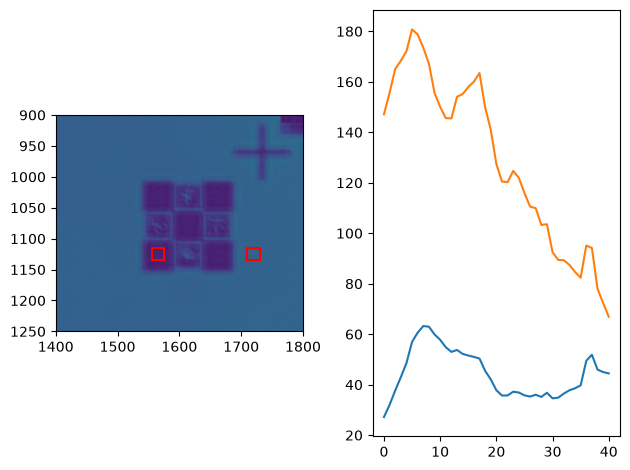

In [15]:
samples = samples_250

ax = plt.subplot(121)
plt.imshow(samples[23])
plt.xlim([1400, 1800])
plt.ylim([1250, 900])
plt.clim([0, 400])

xc1 = 1565
yc1 = 1125
side1 = 20

xc2 = 1720
yc2 = 1125
side2 = 20

squares = [(xc1 - side1//2, yc1 - side1//2, side1), (xc2 - side2//2, yc2 - side2//2, side2)]   # (x, y, side) in pixels
for x, y, s in squares:
    ax.add_patch(Rectangle((x, y), s, s, fill=False, edgecolor="red", linewidth=1.5))

x1, y1, s1 = squares[0]
x2, y2, s2 = squares[1]
plt.subplot(122)
plt.plot(samples[:, y1:y1+s1,x1:x1+s1].mean(axis=(1, 2)))
plt.plot(samples[:, y2:y2+s2,x2:x2+s2].mean(axis=(1, 2)))
#plt.plot(black_frames)

plt.tight_layout()

In [6]:
# Get T_a and T_b

data_weird = np.load("T_weird.npz")
T_a = data_weird["T_a"]
T_b = data_weird["T_b"]

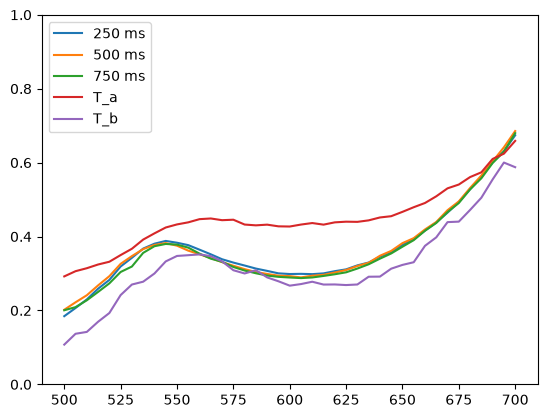

In [16]:
plt.plot(wavelengths, (samples_250[:, y1:y1+s1,x1:x1+s1].mean(axis=(1, 2)))/(refs_250[:, y1:y1+s1,x1:x1+s1].mean(axis=(1, 2))), label='250 ms')
plt.plot(wavelengths, (samples_500[:, y1:y1+s1,x1:x1+s1].mean(axis=(1, 2)))/(refs_500[:, y1:y1+s1,x1:x1+s1].mean(axis=(1, 2))), label='500 ms')
plt.plot(wavelengths, (samples_750[:, y1:y1+s1,x1:x1+s1].mean(axis=(1, 2)))/(refs_750[:, y1:y1+s1,x1:x1+s1].mean(axis=(1, 2))), label='750 ms')
plt.plot(wavelengths, T_a, label="T_a")
plt.plot(wavelengths, T_b, label="T_b")
plt.ylim([0, 1])
plt.legend()

In [17]:
np.save("T_good.npy", (samples_500[:, y1:y1+s1,x1:x1+s1].mean(axis=(1, 2)))/(refs_500[:, y1:y1+s1,x1:x1+s1].mean(axis=(1, 2))))